# Setup Imports Plotting Configuration

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.style.use('seaborn-v0_8-whitegrid')

plt.rcParams['figure.dpi'] =100
np.random.seed(42)

## 1. Gaussian / Normal Distribution

mu= 0.0 , sigma 1.5
emeperical mean {np.float64(-0.07010640044443744)}
emeperical std {np.float64(1.5103281388152126)}
Sample range: min =-4.349270819802722 , max=4.647449151106886


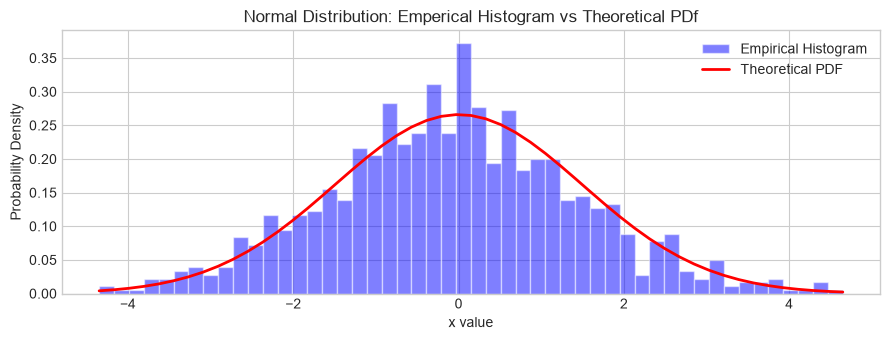

In [8]:
mu , sigma = 0.0,1.5

sample_normal =np.random.normal(mu,sigma,1000)

empirical_mean=np.mean(sample_normal)
empirical_std=np.std(sample_normal)

print("mu=", mu,",","sigma",sigma)
print(f"emeperical mean" , {empirical_mean})
print(f"emeperical std" , {empirical_std})
print(f"Sample range: min ={np.min(sample_normal)} , max={np.max(sample_normal)}")

plt.figure(figsize=(9,3.5))

count,bins,ignored=plt.hist(sample_normal , bins=50,density=True,alpha=0.5,color="blue",edgecolor="white",label="Empirical Histogram")
pdf_normal=stats.norm.pdf(bins , loc=mu,scale=sigma)

plt.plot(bins,pdf_normal , 'r-',linewidth=2,label="Theoretical PDF")

plt.title("Normal Distribution: Emperical Histogram vs Theoretical PDf")
plt.xlabel("x value")
plt.ylabel("Probability Density")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

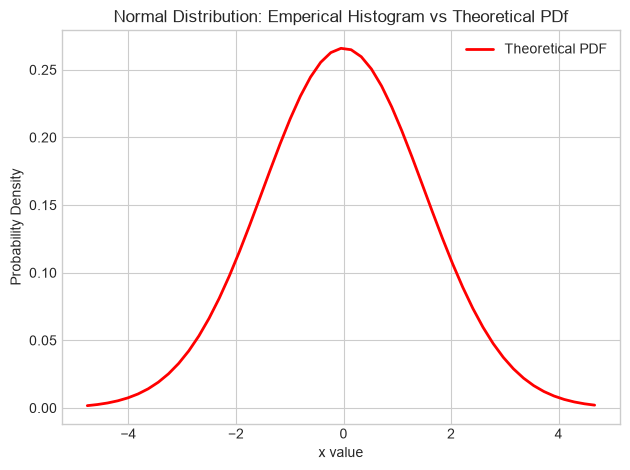

# 2 Continous Uniform Distribution (np.random.uniform)

interval bounds: a:-2.0,b:5.0
Theoretical Mean: 1.5
Theoretical Variance: 1.3333333333333333


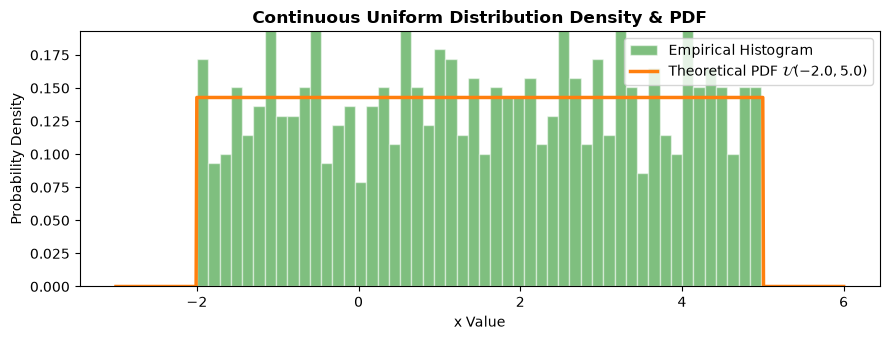

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

a,b = -2.0 , 5.0

samples_uniform=np.random.uniform(a,b,1000)

theoretical_mean=(a+b)/2.0
theoretical_var=((b-1)**2)/12.0

print(f"interval bounds: a:{a},b:{b}")

print(f"Theoretical Mean: {theoretical_mean}")
print(f"Theoretical Variance: {theoretical_var}")

plt.figure(figsize=(9, 3.5))
# density=True normalizes the histogram so that the area under the histogram equals 1
plt.hist(samples_uniform, bins=50, density=True, alpha=0.5, color="green", edgecolor="white", label="Empirical Histogram")

x_axis = np.linspace(a-1.0, b+1.0, 1000)
pdf_uniform = stats.uniform.pdf(x_axis, loc=a, scale=b-a)

plt.plot(x_axis, pdf_uniform, color='#ff7f0e', linewidth=2.5, label=f'Theoretical PDF $\\mathcal{{U}}({a}, {b})$')
plt.title('Continuous Uniform Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('x Value')
plt.ylabel('Probability Density')
plt.ylim(0, 1.0 / (b - a) + 0.05)                    # Set vertical axis slightly above box height
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


# 3. Exponential Distribution (np.random.exponential)

2.0
1.9823462659430697
3.9368839016075357
1.3632657551050726


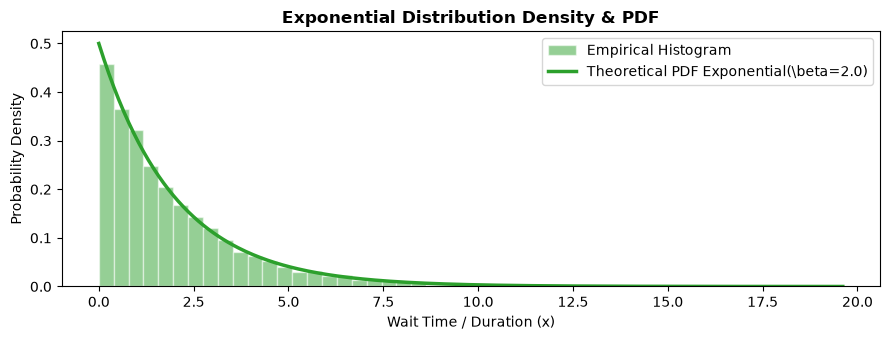

In [4]:
beta_scale=2.0

samples_exp=np.random.exponential(scale=beta_scale,size=10000)

print(beta_scale)
print(np.mean(samples_exp))
print(np.var(samples_exp))
print(np.median(samples_exp))

plt.figure(figsize=(9,3.5))

# Histogram parameters detailed:
# - density=True: Heights scaled to yield unit total area
# - bins=50: Discrete intervals along exponential tail
# - alpha=0.5: Translucency level
# - color='#2ca02c': Forest green
# - edgecolor='white': Sharp boundary outlines
plt.hist(samples_exp, bins=50, density=True, alpha=0.5, color='#2ca02c', edgecolor='white', label='Empirical Histogram')

x_exp = np.linspace(0, np.max(samples_exp), 300)

# stats.expon.pdf Parameters Explained:
# - x (x_exp)         : Array of positive continuous evaluation values starting at 0
# - scale=beta_scale  : Scale parameter beta = 1/lambda matching mean duration (2.0)
pdf_exp = stats.expon.pdf(x_exp, scale=beta_scale)

# Plot formatting parameters detailed:
# - color='#2ca02c': Forest green line curve
# - linewidth=2.5: Line width
plt.plot(x_exp, pdf_exp, color='#2ca02c', linewidth=2.5, label=rf'Theoretical PDF Exponential(\beta={beta_scale})')

plt.title('Exponential Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('Wait Time / Duration (x)')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()



=== COFFEE SHOP DOOR BELL: TIME BETWEEN DINGS ===
Target Average Interval (Minutes) : 2.00
Observed Mean Wait Time          : 1.9550
Observed Variance               : 3.7975 (Theoretical: 4.00)
Median Wait Time Between Dings  : 1.3566



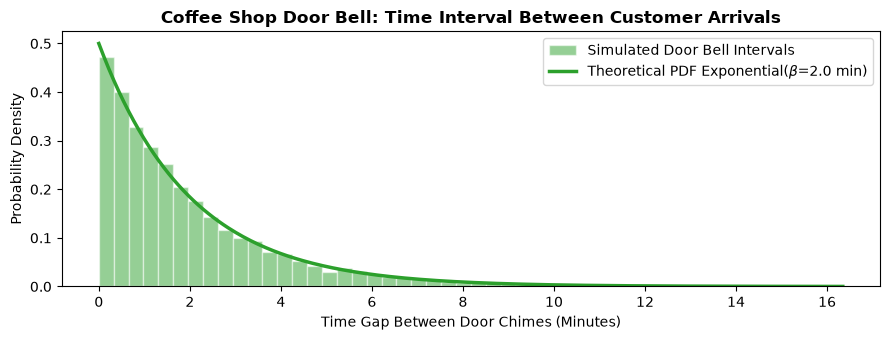

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

avg_wait_minutes = 2.0  # On average, a door bell "Ding!" happens every 2 minutes (lambda = 0.5 dings/min)
num_ding_intervals = 10000

ding_intervals = np.random.exponential(scale=avg_wait_minutes, size=num_ding_intervals)

print("=== COFFEE SHOP DOOR BELL: TIME BETWEEN DINGS ===")
print(f"Target Average Interval (Minutes) : {avg_wait_minutes:.2f}")
print(f"Observed Mean Wait Time          : {np.mean(ding_intervals):.4f}")
print(f"Observed Variance               : {np.var(ding_intervals):.4f} (Theoretical: {avg_wait_minutes**2:.2f})")
print(f"Median Wait Time Between Dings  : {np.median(ding_intervals):.4f}\n")

plt.figure(figsize=(9, 3.5))

plt.hist(ding_intervals, bins=50, density=True, alpha=0.5, color='#2ca02c', edgecolor='white', label='Simulated Door Bell Intervals')

x_intervals = np.linspace(0, np.max(ding_intervals), 300)
pdf_intervals = stats.expon.pdf(x_intervals, scale=avg_wait_minutes)

plt.plot(x_intervals, pdf_intervals, color='#2ca02c', linewidth=2.5, label=rf'Theoretical PDF Exponential($\beta$={avg_wait_minutes} min)')

plt.title('Coffee Shop Door Bell: Time Interval Between Customer Arrivals', fontsize=12, fontweight='bold')
plt.xlabel('Time Gap Between Door Chimes (Minutes)')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 4. Beta Distribution (np.random.beta)

=== 4. BETA DISTRIBUTION OUTPUT ===
Shape Parameters   : alpha = 2.0, beta = 5.0
Theoretical Mean   : 0.2857
Empirical Mean     : 0.2830
Sample Domain      : [0.0007, 0.8359] (Bounded in [0, 1])



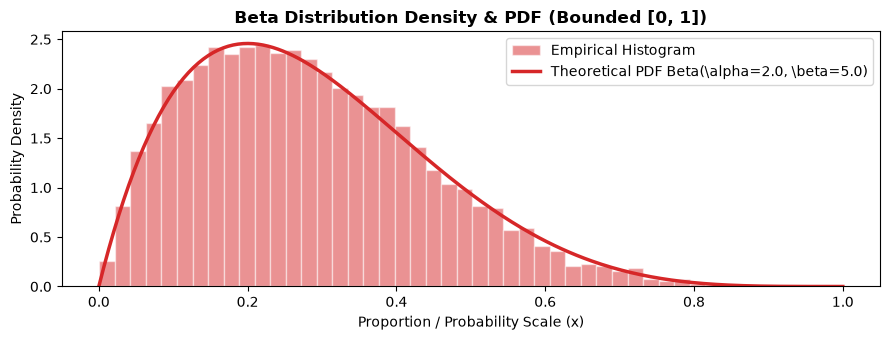

In [6]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
alpha_param, beta_param = 2.0, 5.0                  # Alpha=2 (skewed right towards 0)

# np.random.beta Function Parameters Explained:
# - a=alpha_param : Alpha shape parameter (> 0), controlling probability mass towards 1.0
# - b=beta_param  : Beta shape parameter (> 0), controlling probability mass towards 0.0
# - size=10000    : Number of random probability values sampled within bounded domain [0, 1]
samples_beta = np.random.beta(a=alpha_param, b=beta_param, size=10000)

theoretical_beta_mean = alpha_param / (alpha_param + beta_param)

print("=== 4. BETA DISTRIBUTION OUTPUT ===")
print(f"Shape Parameters   : alpha = {alpha_param:.1f}, beta = {beta_param:.1f}")
print(f"Theoretical Mean   : {theoretical_beta_mean:.4f}")
print(f"Empirical Mean     : {np.mean(samples_beta):.4f}")
print(f"Sample Domain      : [{samples_beta.min():.4f}, {samples_beta.max():.4f}] (Bounded in [0, 1])\n")

# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Scales bin heights so cumulative area equals 1.0
# - bins=40: Discrete intervals across [0, 1] range
# - alpha=0.5: Translucency level
# - color='#d62728': Crimson red
# - edgecolor='white': Sharp boundary outlines
plt.hist(samples_beta, bins=40, density=True, alpha=0.5, color='#d62728', edgecolor='white', label='Empirical Histogram')

x_beta = np.linspace(0, 1, 300)

# stats.beta.pdf Parameters Explained:
# - x (x_beta)     : Bounded evaluation grid strictly from 0 to 1
# - a=alpha_param  : First shape parameter alpha (2.0)
# - b=beta_param   : Second shape parameter beta (5.0)
pdf_beta = stats.beta.pdf(x_beta, a=alpha_param, b=beta_param)

# Plot formatting parameters detailed:
# - color='#d62728': Crimson red line curve
# - linewidth=2.5: Line width
plt.plot(x_beta, pdf_beta, color='#d62728', linewidth=2.5, label=rf'Theoretical PDF Beta(\alpha={alpha_param}, \beta={beta_param})')

plt.title('Beta Distribution Density & PDF (Bounded [0, 1])', fontsize=12, fontweight='bold')
plt.xlabel('Proportion / Probability Scale (x)')
plt.ylabel('Probability Density')
plt.xlim(-0.05, 1.05)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

#  5. Gamma Distribution (np.random.gamma)

=== 5. GAMMA DISTRIBUTION OUTPUT ===
Shape (k) = 3.0, Scale (theta) = 2.0
Theoretical Mean : 6.0000 | Empirical Mean : 6.0182
Theoretical Var  : 12.0000 | Empirical Var  : 12.3374



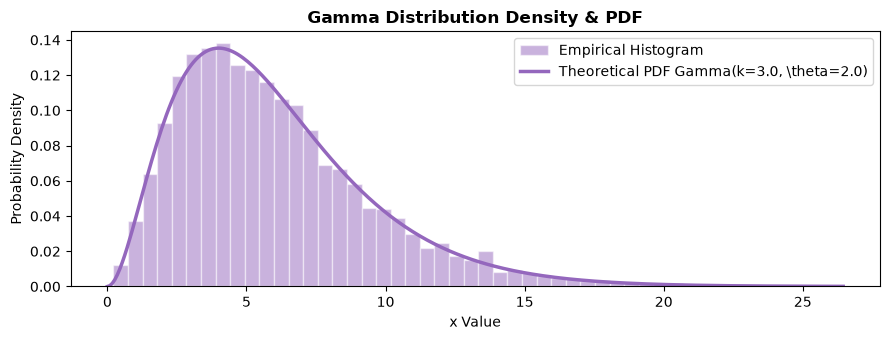

In [7]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
k_shape, theta_scale = 3.0, 2.0                      # k=3 (sum of 3 exponentials), theta=2

# np.random.gamma Function Parameters Explained:
# - shape=k_shape    : Shape parameter k (> 0) controlling profile skewness (3.0)
# - scale=theta_scale: Scale parameter theta (> 0) controlling horizontal stretching (2.0)
# - size=10000       : Number of continuous samples drawn from Gamma process
samples_gamma = np.random.gamma(shape=k_shape, scale=theta_scale, size=10000)

theoretical_gamma_mean = k_shape * theta_scale
theoretical_gamma_var = k_shape * (theta_scale**2)

print("=== 5. GAMMA DISTRIBUTION OUTPUT ===")
print(f"Shape (k) = {k_shape:.1f}, Scale (theta) = {theta_scale:.1f}")
print(f"Theoretical Mean : {theoretical_gamma_mean:.4f} | Empirical Mean : {np.mean(samples_gamma):.4f}")
print(f"Theoretical Var  : {theoretical_gamma_var:.4f} | Empirical Var  : {np.var(samples_gamma):.4f}\n")

# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(figsize=(9, 3.5))

# Histogram parameters detailed:
# - density=True: Scales bin heights to form probability density area of 1.0
# - bins=50: Discrete interval count across continuous range
# - alpha=0.5: Translucency level
# - color='#9467bd': Muted purple
# - edgecolor='white': Sharp contrast outlines
plt.hist(samples_gamma, bins=50, density=True, alpha=0.5, color='#9467bd', edgecolor='white', label='Empirical Histogram')

x_gamma = np.linspace(0, np.max(samples_gamma), 300)

# stats.gamma.pdf Parameters Explained:
# - x (x_gamma)       : Positive evaluation points across continuous domain
# - a=k_shape         : SciPy uses parameter 'a' for shape parameter k (3.0)
# - scale=theta_scale : Scale parameter theta matching scale stretching (2.0)
pdf_gamma = stats.gamma.pdf(x_gamma, a=k_shape, scale=theta_scale)

# Plot formatting parameters detailed:
# - color='#9467bd': Muted purple line curve
# - linewidth=2.5: Line width
plt.plot(x_gamma, pdf_gamma, color='#9467bd', linewidth=2.5, label=rf'Theoretical PDF Gamma(k={k_shape}, \theta={theta_scale})')

plt.title('Gamma Distribution Density & PDF', fontsize=12, fontweight='bold')
plt.xlabel('x Value')
plt.ylabel('Probability Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()